# senseBox:home — temperature by station and time

**Source identity:** the [GreenCity resources page](https://hackathon.greencity.hn/resources) links the `osem_home_data_heilbronn` endpoint from its **senseBox:home** card and describes these as stationary weather stations. The collection currently reports over two million features and may include multiple `boxName` locations. It is not the Mobile Datalogger CSV and is not the raw bike collection.

This notebook scans the collection in `limit`/`offset` pages, keeps measurements for one selected date, and caches only that date locally. Since the API does not provide effective date filtering, a first scan downloads every page; use a stable connection and rerun from the cache afterward.


## Time and comparison caveats

Use `createdAt` as the measurement timestamp and retain `created_at` as the ingestion timestamp. API examples show no timezone offset on `createdAt`; this notebook keeps the timestamp's recorded clock value and does not assume UTC or local time. Confirm the timezone and each station's identity before matching it to the CSV's CEST window.

These are stationary series: compare each `boxName` separately. A fixed station can provide continuous temporal context, but it does not represent every street or route. Check sensor calibration and whether the station is indoors/outdoors or shaded before drawing conclusions about urban heat.


In [1]:
import gzip
import json
import time
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

TARGET_DATE = "2026-09-02"
START_TIME = "10:00"
END_TIME = "14:00"  # exclusive; timestamps are kept as recorded, timezone unverified
PAGE_SIZE = 10_000
REFRESH_CACHE = False
COLLECTION = "osem_home_data_heilbronn"
API_URL = f"https://api.atrai.bike/collections/{COLLECTION}/items"

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
CACHE_DIR = PROJECT_ROOT / "data" / "processed"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_PATH = CACHE_DIR / f"{COLLECTION}_{TARGET_DATE}.csv"
print(f"Collection: {COLLECTION}; cache: {CACHE_PATH}")


Collection: osem_home_data_heilbronn; cache: c:\Users\marce\Documents\GitHub\Tree-Mendous\data\processed\osem_home_data_heilbronn_2026-09-02.csv


In [2]:
def get_json_page(offset):
    request_url = f"{API_URL}?f=json&limit={PAGE_SIZE}&offset={offset}"
    request = Request(request_url, headers={"Accept-Encoding": "gzip"})
    with urlopen(request, timeout=90) as response:
        body = response.read()
        if response.headers.get("Content-Encoding") == "gzip":
            body = gzip.decompress(body)
    return json.loads(body)


def fetch_home_day():
    if CACHE_PATH.exists() and not REFRESH_CACHE:
        print("Using cached measurements. Set REFRESH_CACHE=True to rescan the API.")
        return pd.read_csv(CACHE_PATH)

    selected = []
    offset = 0
    total = None
    while total is None or offset < total:
        page = get_json_page(offset)
        total = page["numberMatched"]
        features = page.get("features", [])
        for feature in features:
            properties = feature.get("properties", {})
            timestamp = properties.get("createdAt")
            if not isinstance(timestamp, str) or timestamp[:10] != TARGET_DATE:
                continue
            row = dict(properties)
            coordinates = feature.get("geometry", {}).get("coordinates") or []
            if len(coordinates) >= 2:
                row["longitude"] = coordinates[0]
                row["latitude"] = coordinates[1]
            selected.append(row)

        returned = page.get("numberReturned", len(features))
        if returned == 0:
            break
        offset += returned
        if offset % (PAGE_SIZE * 10) == 0 or offset >= total:
            print(f"Scanned {min(offset, total):,} / {total:,} features; matched {len(selected):,} rows for {TARGET_DATE}.")
        time.sleep(0.1)

    if not selected:
        raise ValueError(f"No senseBox:home measurements found for {TARGET_DATE}.")
    result = pd.DataFrame(selected)
    result.to_csv(CACHE_PATH, index=False)
    print(f"Cached {len(result):,} matching measurements at {CACHE_PATH}")
    return result


home = fetch_home_day()
required = {"createdAt", "Temperature", "longitude", "latitude", "boxName"}
missing = required.difference(home.columns)
if missing:
    raise ValueError(f"API response is missing expected fields: {sorted(missing)}")
home["measurement_time"] = pd.to_datetime(home["createdAt"], errors="coerce")
home["Temperature"] = pd.to_numeric(home["Temperature"], errors="coerce")
home["longitude"] = pd.to_numeric(home["longitude"], errors="coerce")
home["latitude"] = pd.to_numeric(home["latitude"], errors="coerce")
home = home.dropna(subset=["measurement_time", "Temperature", "longitude", "latitude"]).copy()
print(f"Usable rows: {len(home):,}; station names: {home['boxName'].nunique()}")
display(home[["createdAt", "boxName", "Temperature", "Rel. Humidity", "longitude", "latitude"]].head())


Scanned 100,000 / 2,026,306 features; matched 1,428 rows for 2026-09-02.
Scanned 200,000 / 2,026,306 features; matched 1,428 rows for 2026-09-02.
Scanned 300,000 / 2,026,306 features; matched 1,428 rows for 2026-09-02.
Scanned 400,000 / 2,026,306 features; matched 1,428 rows for 2026-09-02.
Scanned 500,000 / 2,026,306 features; matched 1,428 rows for 2026-09-02.
Scanned 600,000 / 2,026,306 features; matched 1,428 rows for 2026-09-02.
Scanned 700,000 / 2,026,306 features; matched 1,428 rows for 2026-09-02.
Scanned 800,000 / 2,026,306 features; matched 1,471 rows for 2026-09-02.
Scanned 900,000 / 2,026,306 features; matched 1,471 rows for 2026-09-02.
Scanned 1,000,000 / 2,026,306 features; matched 1,471 rows for 2026-09-02.
Scanned 1,100,000 / 2,026,306 features; matched 1,471 rows for 2026-09-02.
Scanned 1,200,000 / 2,026,306 features; matched 6,902 rows for 2026-09-02.
Scanned 1,300,000 / 2,026,306 features; matched 6,902 rows for 2026-09-02.
Scanned 1,400,000 / 2,026,306 features; mat

,createdAt,boxName,Temperature,Rel. Humidity,longitude,latitude
0,2026-09-02T00:00:21.363,HCG Beilstein,29.26,38.22,9.309658,49.04376
1,2026-09-02T00:01:22.632,HCG Beilstein,29.29,38.22,9.309658,49.04376
2,2026-09-02T00:02:21.222,HCG Beilstein,29.18,38.22,9.309658,49.04376
3,2026-09-02T00:03:21.36,HCG Beilstein,29.23,38.22,9.309658,49.04376
4,2026-09-02T00:04:21.327,HCG Beilstein,29.17,38.22,9.309658,49.04376


## Inspect stations before comparing them

Use this overview to see which station names and coordinates actually appear on the selected date. Do not average different stations together unless that is an intentional regional summary.


In [3]:
stations = home.groupby("boxName").agg(
    readings=("Temperature", "count"),
    latitude=("latitude", "median"),
    longitude=("longitude", "median"),
    first_recorded=("measurement_time", "min"),
    last_recorded=("measurement_time", "max"),
    mean_temperature_c=("Temperature", "mean"),
).sort_values("readings", ascending=False)
stations[["latitude", "longitude"]] = stations[["latitude", "longitude"]].round(4)
stations["mean_temperature_c"] = stations["mean_temperature_c"].round(2)
display(stations)


,readings,latitude,longitude,first_recorded,last_recorded,mean_temperature_c
boxName,,,,,,
SenseBox Wolf-von-Gemmingen-Schule,5424,49.1571,8.9893,2026-09-02 06:43:32.179,2026-09-02 23:59:42.094,24.48
HCG Beilstein,2852,49.0438,9.3097,2026-09-02 00:00:21.363,2026-09-02 23:59:06.988,29.46
Innenstadt,281,49.1425,9.2220,2026-09-02 00:03:52.156,2026-09-02 23:57:50.147,22.17
THW Heilbronn,169,49.1623,9.2191,2026-09-02 00:00:00.374,2026-09-02 14:00:00.347,18.80
GreenCity OpenSpace,43,49.1517,9.2153,2026-09-02 00:00:15.495,2026-09-02 00:52:10.613,19.40


## Temperature in one date/time window

The end time is exclusive. Results are grouped by station and recorded clock hour, preserving each fixed sensor's independent time series.


In [4]:
window_start = pd.Timestamp(f"{TARGET_DATE} {START_TIME}")
window_end = pd.Timestamp(f"{TARGET_DATE} {END_TIME}")
if window_end <= window_start:
    raise ValueError("END_TIME must be later than START_TIME on the selected date.")

window = home.loc[
    (home["measurement_time"] >= window_start)
    & (home["measurement_time"] < window_end)
].copy()
if window.empty:
    raise ValueError("No home-station temperature readings fall within this date/time window.")
window["recorded_hour"] = window["measurement_time"].dt.strftime("%H:00")
hourly = window.groupby(["boxName", "recorded_hour"]).agg(
    first_reading=("measurement_time", "min"),
    last_reading=("measurement_time", "max"),
    readings=("Temperature", "count"),
    mean_temperature_c=("Temperature", "mean"),
    median_temperature_c=("Temperature", "median"),
    min_temperature_c=("Temperature", "min"),
    max_temperature_c=("Temperature", "max"),
).sort_index()
hourly["first_reading"] = hourly["first_reading"].dt.strftime("%H:%M:%S")
hourly["last_reading"] = hourly["last_reading"].dt.strftime("%H:%M:%S")
display(hourly.round(2))
print(f"Recorded-time window: {window_start} <= time < {window_end} (timezone not specified by API sample).")
print(f"Stations in window: {window['boxName'].nunique()}; rows: {len(window):,}")


first_reading last_reading  \
boxName                            recorded_hour                              
HCG Beilstein                      10:00              10:00:16     10:59:19   
                                   11:00              11:00:16     11:59:15   
                                   12:00              12:00:16     12:59:15   
                                   13:00              13:00:15     13:59:15   
Innenstadt                         10:00              10:00:55     10:57:03   
                                   11:00              11:02:09     11:58:17   
                                   12:00              12:03:23     12:59:30   
                                   13:00              13:04:37     13:55:38   
SenseBox Wolf-von-Gemmingen-Schule 10:00              10:00:11     10:59:54   
                                   11:00              11:00:04     11:59:55   
                                   12:00              12:00:05     12:59:50   
                                   13:00              13:00:00     13:59:51   
THW Heilbronn                      10:00              10:00:00     10:55:00   
                                   11:00              11:00:00     11:55:00   
                                   12:00              12:00:00     12:55:00   
                                   13:00              13:00:00     13:55:00   

                                                  readings  \
boxName                            recorded_hour             
HCG Beilstein                      10:00               120   
                                   11:00               120   
                                   12:00               120   
                                   13:00               120   
Innenstadt                         10:00                12   
                                   11:00                12   
                                   12:00                12   
                                   13:00                11   
SenseBox Wolf-von-Gemmingen-Schule 10:00               325   
                                   11:00               320   
                                   12:00               324   
                                   13:00               323   
THW Heilbronn                      10:00                12   
                                   11:00                12   
                                   12:00                12   
                                   13:00                12   

                                                  mean_temperature_c  \
boxName                            recorded_hour                       
HCG Beilstein                      10:00                       28.98   
                                   11:00                       29.25   
                                   12:00                       29.55   
                                   13:00                       30.40   
Innenstadt                         10:00                       25.74   
                                   11:00                       26.73   
                                   12:00                       28.67   
                                   13:00                       28.55   
SenseBox Wolf-von-Gemmingen-Schule 10:00                       24.20   
                                   11:00                       24.51   
                                   12:00                       24.80   
                                   13:00                       25.05   
THW Heilbronn                      10:00                       24.85   
                                   11:00                       27.02   
                                   12:00                       27.59   
                                   13:00                       27.62   

                                                  median_temperature_c  \
boxName                            recorded_hour                         
HCG Beilstein                      10:00                        

Recorded-time window: 2026-09-02 10:00:00 <= time < 2026-09-02 14:00:00 (timezone not specified by API sample).
Stations in window: 4; rows: 1,867


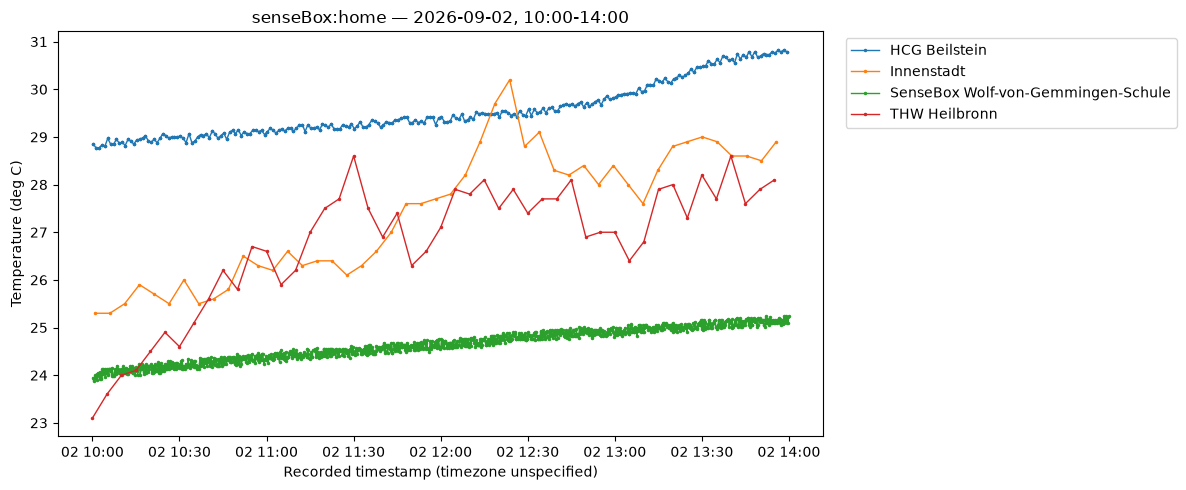

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
for box_name, readings in window.groupby("boxName"):
    series = readings.set_index("measurement_time")["Temperature"].sort_index()
    ax.plot(series.index, series.values, marker=".", markersize=3, linewidth=1, label=box_name)
ax.set(title=f"senseBox:home — {TARGET_DATE}, {START_TIME}-{END_TIME}", xlabel="Recorded timestamp (timezone unspecified)", ylabel="Temperature (deg C)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


## How to use this source responsibly

- `createdAt` is the measurement time; `created_at` is the ingestion time. Keep both when investigating delayed uploads.
- `osem_home_data_heilbronn` is a collection name, not a guarantee that every record is a single station or lies within the city boundary. Inspect `boxName` and coordinates for the date of interest.
- The API sample timestamps have no timezone suffix. Do not convert them or claim an exact overlap with the Mobile Datalogger's UTC-derived CEST times until the provider confirms the timestamp convention.
- The date cache is written to `data/processed/`. Set `REFRESH_CACHE = True` to rescan the API.
- Compare station temperatures per `boxName`, at the same confirmed time interval, and with sensor placement/calibration in mind. Do not merge this stationary series with bike or walking route points as if they were equivalent observations.
